In [46]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import logging
from datetime import datetime, timedelta
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, log_loss
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
import optuna
import time
import json

In [47]:
# Configuration des visualisations
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['font.size'] = 12
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Configuration du logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

def load_data():
    """Charge les données du fichier CSV et effectue les conversions de base"""
    # Définir le chemin vers le fichier
    file_path = Path.home() / "Desktop" / "f1_data_overtake.csv"

    # Vérifier l'existence du fichier
    if not file_path.exists():
        raise FileNotFoundError(f"Le fichier {file_path} n'existe pas")

    # Charger les données
    logger.info("Chargement des données...")
    df = pd.read_csv(file_path, index_col=0)

    # Conversion des colonnes de date
    date_columns = [col for col in df.columns if 'date' in col.lower()]
    for col in date_columns:
        df[col] = pd.to_datetime(df[col], format='mixed', utc=True)

    logger.info(f"Données chargées : {df.shape[0]} lignes et {df.shape[1]} colonnes")
    return df

In [48]:
def split_data_chronologically(X, y, session_keys, categorical_features, label_encoder):
    """Divise les données en ensembles d'entraînement et de test en respectant l'ordre chronologique des courses.

    Args:
        X (pd.DataFrame): Features
        y (np.array): Labels encodés
        session_keys (pd.Series): Clés de session pour le split (utilisées pour le logging)
        categorical_features (list): Liste des features catégorielles
        label_encoder (LabelEncoder): Encodeur des labels

    Returns:
        tuple: X_train, X_test, y_train, y_test, categorical_features, label_encoder
    """
    logger.info("Division des données en respectant l'ordre chronologique...")

    # 1. Trouver la date de split (47ème session unique après le tri)
    unique_session_dates = sorted(X['session_date_start'].unique())

    # Assurer qu'il y a suffisamment de sessions uniques
    if len(unique_session_dates) < 47:
        error_msg = f"Pas assez de sessions uniques pour effectuer le split (seulement {len(unique_session_dates)})."
        logger.error(error_msg)
        raise ValueError(error_msg)

    split_date = unique_session_dates[46]
    logger.info(f"Date de split (47ème date de session unique) : {split_date}")

    # 2. Diviser les données en fonction de la date de split
    X_train = X[X['session_date_start'] < split_date]
    X_test = X[X['session_date_start'] >= split_date]
    y_train = y[X['session_date_start'] < split_date]
    y_test = y[X['session_date_start'] >= split_date]

    # Logging des statistiques
    logger.info(f"Nombre total de sessions uniques : {len(unique_session_dates)}")
    logger.info(f"Sessions uniques (triées par date) : {unique_session_dates}")
    logger.info(f"Features catégorielles ({len(categorical_features)}): {', '.join(categorical_features)}")
    logger.info(f"Features temporelles ({len(X.select_dtypes(include=['datetime64[ns, UTC]']).columns)})")
    logger.info(f"Distribution des classes (train):\n{pd.Series(y_train).value_counts(normalize=True)}")
    logger.info(f"Distribution des classes (test):\n{pd.Series(y_test).value_counts(normalize=True)}")
    logger.info(f"Nombre de courses dans l'ensemble d'entraînement: {len(X_train['session_key'].unique())}")
    logger.info(f"Nombre de courses dans l'ensemble de test: {len(X_test['session_key'].unique())}")

    return X_train, X_test, y_train, y_test, categorical_features, label_encoder

In [49]:
def prepare_data(df):
    """Prépare les données pour l'entraînement du modèle."""
    logger.info("Préparation des données...")

    # Afficher la distribution initiale de will_overtake
    logger.info("\nDistribution initiale de will_overtake:")
    logger.info(df['will_overtake'].value_counts(dropna=False))

    # On ne supprime que les NA, on garde les "Unknown"
    logger.info(f"\nNombre de lignes avant filtrage des NA: {len(df)}")
    df = df[df['will_overtake'].notna()]
    logger.info(f"Nombre de lignes après filtrage des NA: {len(df)}")

    # Trier les données
    logger.info("Tri des données par session_date_start, driver_number, et lap_number...")
    df = df.sort_values(by=['session_date_start', 'driver_number', 'lap_number'])
    
    # Séparation des features et de la target
    X = df.drop('will_overtake', axis=1)
    y = df['will_overtake']

    # Conversion des labels en entiers
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y)
    logger.info(f"\nClasses encodées: {dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))}")

    # Conversion des colonnes catégorielles
    categorical_features = []
    for col in X.columns:
        if X[col].dtype.name in ['object', 'category']:
            # Remplacer les NA par une catégorie "Unknown" pour les variables catégorielles
            X[col] = X[col].fillna('Unknown')
            X[col] = pd.Categorical(X[col])
            categorical_features.append(col)

    # Conversion des dates
    date_cols = X.select_dtypes(include=['datetime64[ns, UTC]']).columns
    for col in date_cols:
        X[col] = pd.to_numeric(X[col], errors='coerce') / 1e9

    # Pour les colonnes numériques, remplacer les NA par la médiane
    numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
    for col in numeric_cols:
        X[col] = X[col].fillna(X[col].median())

    # Split chronologique des données
    return split_data_chronologically(X, y, df['session_key'], categorical_features, label_encoder)

In [50]:
def objective(trial, X_train, y_train, categorical_cols):
    """Fonction objectif pour l'optimisation des hyperparamètres avec Optuna pour une classification binaire."""
    try:
        param = {
            # Paramètres de base pour classification binaire
            "objective": "binary",  # Changé pour classification binaire
            'metric': ['binary_logloss', 'auc'],  # Métriques adaptées
            'boosting_type': 'gbdt',
            'verbosity': -1,
            'boost_from_average': True,
            'seed': 42,

            # Paramètres de régularisation
            'lambda_l1': trial.suggest_float('lambda_l1', 0, 3),
            'lambda_l2': trial.suggest_float('lambda_l2', 0, 3),
            'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0, 2),

            # Paramètres de l'arbre
            'num_leaves': trial.suggest_int('num_leaves', 90, 150),
            'max_depth': trial.suggest_int('max_depth', 6, 12),
            'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 10, 50),
            'min_sum_hessian_in_leaf': trial.suggest_float('min_sum_hessian_in_leaf', 2, 4),

            # Paramètres de sous-échantillonnage
            'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 0.9),
            'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 0.6),
            'bagging_freq': trial.suggest_int('bagging_freq', 5, 7),

            # Paramètres d'apprentissage
            'learning_rate': trial.suggest_float('learning_rate', 0.07, 0.1),

            # Paramètres de binning
            "max_bin": trial.suggest_int("max_bin", 100, 200),
            "min_data_in_bin": trial.suggest_int("min_data_in_bin", 10, 20),

            # Paramètres pour les catégorielles
            "cat_smooth": trial.suggest_float("cat_smooth", 80, 100),
            
            # Paramètres spécifiques pour gérer le déséquilibre des classes
            'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10)  # Poids pour la classe minoritaire
        }

        # Dataset LightGBM avec gestion explicite des catégorielles
        dtrain = lgb.Dataset(
            X_train,
            label=y_train.astype(int),
            categorical_feature=list(categorical_cols),
            feature_name=list(X_train.columns)
        )

        # CV avec early stopping
        cv_results = lgb.cv(
            params=param,
            train_set=dtrain,
            num_boost_round=2000,
            nfold=5,
            stratified=True,  # Important pour maintenir la distribution des classes
            seed=42,
            callbacks=[
                lgb.early_stopping(stopping_rounds=200, verbose=True),
                lgb.log_evaluation(period=0)
            ],
            return_cvbooster=True
        )

        # Récupération du meilleur score et de la meilleure itération
        best_score = min(cv_results['valid binary_logloss-mean'])  # Changé pour binary_logloss
        best_iter = len(cv_results['valid binary_logloss-mean'])

        if not np.isfinite(best_score):
            logger.warning(f"Score non valide obtenu: {best_score}")
            return float('inf')

        # Récupérer aussi l'AUC pour le logging
        best_auc = max(cv_results['valid auc-mean'])
        logger.info(f"Trial terminé - Loss: {best_score:.4f}, AUC: {best_auc:.4f} à l'itération {best_iter}")
        
        # Stocker la meilleure itération et l'AUC
        trial.set_user_attr("best_iteration", best_iter)
        trial.set_user_attr("best_auc", best_auc)

        return best_score

    except Exception as e:
        logger.error(f"Erreur dans l'objectif: {str(e)}")
        return float('inf')

In [51]:
def train_final_model(study, X_train, X_test, y_train, y_test, cat_features):
    """
    Entraîne le modèle final avec les meilleurs paramètres trouvés pour une classification binaire.
    """
    logger.info("Entraînement du modèle final...")

    best_params = study.best_params
    best_iteration = study.best_trial.user_attrs["best_iteration"]

    # Ajustement des paramètres pour le modèle final
    final_params = {
        **best_params,
        'objective': 'binary',  # Classification binaire
        'metric': ['binary_logloss', 'auc'],  # Métriques binaires
        'categorical_feature': cat_features,
        'learning_rate': best_params['learning_rate'] * 0.8,
        'boost_from_average': True
    }

    # Création des datasets
    train_data = lgb.Dataset(
        X_train,
        label=y_train,
        categorical_feature=cat_features,
        feature_name=list(X_train.columns)
    )
    valid_data = lgb.Dataset(
        X_test,
        label=y_test,
        reference=train_data,
        feature_name=list(X_test.columns)
    )

    # Entraînement avec early stopping
    final_model = lgb.train(
        final_params,
        train_data,
        num_boost_round=int(best_iteration * 1.2),
        valid_sets=[valid_data],
        callbacks=[
            lgb.early_stopping(stopping_rounds=200, verbose=True),
            lgb.log_evaluation(period=100)
        ]
    )

    logger.info(f"Entraînement terminé après {final_model.best_iteration} itérations")

    # Évaluation du modèle final
    y_pred_prob = final_model.predict(X_test)

    # Calcul des métriques
    final_logloss = log_loss(y_test, y_pred_prob)

    # Affichage des résultats
    logger.info("\nRésultats du modèle final:")
    logger.info(f"Log loss: {final_logloss:.4f}")

    return final_model

In [52]:
def evaluate_model_with_probabilities(model, X_test, y_test, threshold=0.5):
    """Évalue le modèle avec analyse détaillée des probabilités pour une classification binaire"""
    logger.info("Évaluation du modèle et analyse des probabilités...")

    # Obtention des probabilités
    y_pred_proba = model.predict(X_test)
    y_pred_classes = (y_pred_proba > threshold).astype(int)

    # Calcul des métriques de base
    class_labels = ['Pas de dépassement', 'Dépassement']
    
    # Rapport de classification standard
    report = classification_report(y_test, y_pred_classes)
    logger.info("\nRapport de classification:\n" + report)

    # Analyse des probabilités
    logger.info("\nAnalyse des probabilités:")
    
    # Pour les vrais positifs et négatifs
    true_pos_mask = (y_test == 1)
    mean_proba_true_pos = y_pred_proba[true_pos_mask].mean()
    mean_proba_true_neg = y_pred_proba[~true_pos_mask].mean()
    
    logger.info(f"\nProbabilités moyennes:")
    logger.info(f"- Pour les vrais dépassements: {mean_proba_true_pos:.3f}")
    logger.info(f"- Pour les non-dépassements: {mean_proba_true_neg:.3f}")

    # Visualisations
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 16))

    # 1. Feature importance
    feature_imp = pd.DataFrame({
        'feature': model.feature_name(),
        'importance': model.feature_importance('gain')
    }).sort_values('importance', ascending=False)

    sns.barplot(data=feature_imp.head(15), x='importance', y='feature', ax=ax1)
    ax1.set_title('Top 15 Features Importantes', fontsize=12)

    # 2. Matrice de confusion
    conf_matrix = confusion_matrix(y_test, y_pred_classes)
    sns.heatmap(
        conf_matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax2,
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    ax2.set_title('Matrice de Confusion', fontsize=12)
    
    # 3. Distribution des probabilités par classe réelle
    sns.boxplot(
        x=y_test,
        y=y_pred_proba,
        ax=ax3
    )
    ax3.set_title('Distribution des Probabilités par Classe Réelle', fontsize=12)
    ax3.set_xlabel('Classe Réelle (0: Pas de dépassement, 1: Dépassement)')
    ax3.set_ylabel('Probabilité Prédite de Dépassement')
    
    # 4. Histogramme des probabilités
    sns.histplot(
        data=pd.DataFrame({
            'Probabilité': y_pred_proba,
            'Classe Réelle': ['Dépassement' if y == 1 else 'Pas de dépassement' for y in y_test]
        }),
        x='Probabilité',
        hue='Classe Réelle',
        bins=50,
        ax=ax4
    )
    ax4.set_title('Distribution des Probabilités', fontsize=12)

    plt.tight_layout()

    # Calcul des métriques additionnelles
    precision = precision_score(y_test, y_pred_classes)
    recall = recall_score(y_test, y_pred_classes)
    f1 = f1_score(y_test, y_pred_classes)
    auc = roc_auc_score(y_test, y_pred_proba)

    logger.info(f"\nMétriques additionnelles:")
    logger.info(f"Précision: {precision:.3f}")
    logger.info(f"Rappel: {recall:.3f}")
    logger.info(f"F1-Score: {f1:.3f}")
    logger.info(f"AUC-ROC: {auc:.3f}")

    return fig, report, feature_imp, y_pred_proba

In [53]:
# Définition d'un callback sécurisé
def log_trial_value(study, trial):
    """Callback sécurisé pour le logging des essais"""
    try:
        if trial.value is not None:
            logger.info(f"Trial {trial.number}: score={trial.value:.4f}")
        else:
            logger.info(f"Trial {trial.number}: PRUNED")
    except Exception as e:
        logger.error(f"Erreur dans le callback: {str(e)}")

In [54]:
start_time = datetime.now()
logger.info("Début du processus d'entraînement")
    
# Chargement et préparation des données
df = load_data()
X_train, X_test, y_train, y_test, cat_features, label_encoder = prepare_data(df)

2025-01-19 02:25:34,110 - INFO - Début du processus d'entraînement
2025-01-19 02:25:34,112 - INFO - Chargement des données...
2025-01-19 02:25:34,345 - INFO - Données chargées : 55290 lignes et 64 colonnes
2025-01-19 02:25:34,351 - INFO - Préparation des données...
2025-01-19 02:25:34,351 - INFO - 
Distribution initiale de will_overtake:
2025-01-19 02:25:34,352 - INFO - will_overtake
False    53353
True      1937
Name: count, dtype: int64
2025-01-19 02:25:34,353 - INFO - 
Nombre de lignes avant filtrage des NA: 55290
2025-01-19 02:25:34,364 - INFO - Nombre de lignes après filtrage des NA: 55290
2025-01-19 02:25:34,365 - INFO - Tri des données par session_date_start, driver_number, et lap_number...
2025-01-19 02:25:34,395 - INFO - 
Classes encodées: {np.False_: 0, np.True_: 1}
2025-01-19 02:25:34,485 - INFO - Division des données en respectant l'ordre chronologique...
2025-01-19 02:25:34,488 - INFO - Date de split (47ème date de session unique) : 1725195902.563
2025-01-19 02:25:34,504 -

In [55]:
# Optimisation avec Optuna
logger.info("Début de l'optimisation des hyperparamètres...")
study = optuna.create_study(
    direction='minimize',
    study_name=f"lightgbm_pit_stop_{datetime.now().strftime('%Y%m%d_%H%M')}"
)

study.optimize(
    lambda trial: objective(trial, X_train, y_train, cat_features),
    n_trials=50,
    n_jobs=1,
    callbacks=[log_trial_value]
)

2025-01-19 02:25:34,553 - INFO - Début de l'optimisation des hyperparamètres...
[I 2025-01-19 02:25:34,554] A new study created in memory with name: lightgbm_pit_stop_20250119_0225


Training until validation scores don't improve for 200 rounds


2025-01-19 02:26:04,187 - INFO - Trial terminé - Loss: 0.0897, AUC: 0.9482 à l'itération 112
[I 2025-01-19 02:26:04,204] Trial 0 finished with value: 0.08968529889530041 and parameters: {'lambda_l1': 2.8528080026250144, 'lambda_l2': 0.3500831068785767, 'min_gain_to_split': 1.7908514771521389, 'num_leaves': 138, 'max_depth': 11, 'min_data_in_leaf': 28, 'min_sum_hessian_in_leaf': 2.446176814821264, 'feature_fraction': 0.8012817713500271, 'bagging_fraction': 0.5515163421208843, 'bagging_freq': 5, 'learning_rate': 0.0823778788735948, 'max_bin': 187, 'min_data_in_bin': 14, 'cat_smooth': 83.13570222103506, 'scale_pos_weight': 4.752661014625813}. Best is trial 0 with value: 0.08968529889530041.
2025-01-19 02:26:04,205 - INFO - Trial 0: score=0.0897


Early stopping, best iteration is:
[112]	cv_agg's valid binary_logloss: 0.089709 + 0.00215836	cv_agg's valid auc: 0.948239 + 0.00461557
Training until validation scores don't improve for 200 rounds


2025-01-19 02:26:31,844 - INFO - Trial terminé - Loss: 0.1047, AUC: 0.9478 à l'itération 121
[I 2025-01-19 02:26:31,856] Trial 1 finished with value: 0.10466643233426401 and parameters: {'lambda_l1': 0.6879126023046404, 'lambda_l2': 1.5678911488140337, 'min_gain_to_split': 1.6298031222127776, 'num_leaves': 115, 'max_depth': 6, 'min_data_in_leaf': 41, 'min_sum_hessian_in_leaf': 3.4565430376698894, 'feature_fraction': 0.8429877632626506, 'bagging_fraction': 0.477315483836461, 'bagging_freq': 5, 'learning_rate': 0.0728472409685501, 'max_bin': 153, 'min_data_in_bin': 12, 'cat_smooth': 96.68401674072382, 'scale_pos_weight': 6.347447306147151}. Best is trial 0 with value: 0.08968529889530041.
2025-01-19 02:26:31,857 - INFO - Trial 1: score=0.1047


...

Early stopping, best iteration is:
[96]	cv_agg's valid binary_logloss: 0.0807157 + 0.00125681	cv_agg's valid auc: 0.949329 + 0.00351146
Training until validation scores don't improve for 200 rounds


2025-01-19 02:47:14,068 - INFO - Trial terminé - Loss: 0.0984, AUC: 0.9475 à l'itération 96
[I 2025-01-19 02:47:14,080] Trial 48 finished with value: 0.09838317946577899 and parameters: {'lambda_l1': 2.135704713996579, 'lambda_l2': 2.6630621958775653, 'min_gain_to_split': 1.3440595846439722, 'num_leaves': 125, 'max_depth': 7, 'min_data_in_leaf': 24, 'min_sum_hessian_in_leaf': 3.5822178465230183, 'feature_fraction': 0.5552703858370179, 'bagging_fraction': 0.5710722607078113, 'bagging_freq': 6, 'learning_rate': 0.09557820284260908, 'max_bin': 155, 'min_data_in_bin': 19, 'cat_smooth': 92.78622905488174, 'scale_pos_weight': 5.97051404923089}. Best is trial 41 with value: 0.07912357731017487.
2025-01-19 02:47:14,081 - INFO - Trial 48: score=0.0984


Early stopping, best iteration is:
[96]	cv_agg's valid binary_logloss: 0.0983832 + 0.00165407	cv_agg's valid auc: 0.947536 + 0.00488722
Training until validation scores don't improve for 200 rounds


2025-01-19 02:47:41,411 - INFO - Trial terminé - Loss: 0.0800, AUC: 0.9499 à l'itération 266
[I 2025-01-19 02:47:41,425] Trial 49 finished with value: 0.07995612585039998 and parameters: {'lambda_l1': 0.3562838841392497, 'lambda_l2': 2.835365001725346, 'min_gain_to_split': 1.7524163307151202, 'num_leaves': 130, 'max_depth': 6, 'min_data_in_leaf': 21, 'min_sum_hessian_in_leaf': 3.6977393951081003, 'feature_fraction': 0.5165918783230682, 'bagging_fraction': 0.5994504923523641, 'bagging_freq': 6, 'learning_rate': 0.09389662623242581, 'max_bin': 136, 'min_data_in_bin': 20, 'cat_smooth': 98.386132926972, 'scale_pos_weight': 1.093853170042951}. Best is trial 41 with value: 0.07912357731017487.
2025-01-19 02:47:41,426 - INFO - Trial 49: score=0.0800


Early stopping, best iteration is:
[266]	cv_agg's valid binary_logloss: 0.0799561 + 0.0014292	cv_agg's valid auc: 0.949868 + 0.00383927


In [56]:
# Vérification avant d'accéder aux meilleurs paramètres
if study.best_trials:
    best_params = study.best_params
    logger.info(f"Meilleurs paramètres trouvés: {best_params}")

    # Entraînement du modèle final
    best_iteration = study.best_trial.user_attrs["best_iteration"]
    final_model = train_final_model(
    study, X_train, X_test, y_train, y_test, cat_features
)

else:
    logger.error("Aucun essai terminé avec succès. Impossible d'entraîner le modèle final.")

2025-01-19 02:47:41,443 - INFO - Meilleurs paramètres trouvés: {'lambda_l1': 0.017895104076582354, 'lambda_l2': 2.905766818768949, 'min_gain_to_split': 1.989093221706731, 'num_leaves': 124, 'max_depth': 6, 'min_data_in_leaf': 26, 'min_sum_hessian_in_leaf': 3.974634867456132, 'feature_fraction': 0.5121304518241667, 'bagging_fraction': 0.5990906038827934, 'bagging_freq': 6, 'learning_rate': 0.0903038385374324, 'max_bin': 133, 'min_data_in_bin': 19, 'cat_smooth': 99.8932948468613, 'scale_pos_weight': 1.0639549182671604}
2025-01-19 02:47:41,444 - INFO - Entraînement du modèle final...


Training until validation scores don't improve for 200 rounds
[100]	valid_0's binary_logloss: 0.0760857	valid_0's auc: 0.943088
[200]	valid_0's binary_logloss: 0.0751007	valid_0's auc: 0.943343
[300]	valid_0's binary_logloss: 0.0744491	valid_0's auc: 0.944666


2025-01-19 02:47:46,070 - INFO - Entraînement terminé après 291 itérations
2025-01-19 02:47:46,086 - INFO - 
Résultats du modèle final:
2025-01-19 02:47:46,087 - INFO - Log loss: 0.0744


Did not meet early stopping. Best iteration is:
[291]	valid_0's binary_logloss: 0.0744148	valid_0's auc: 0.944567


2025-01-19 02:47:46,096 - INFO - Évaluation du modèle et analyse des probabilités...
2025-01-19 02:47:46,118 - INFO - 
Rapport de classification:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99     10178
           1       0.62      0.48      0.54       334

    accuracy                           0.97     10512
   macro avg       0.80      0.74      0.76     10512
weighted avg       0.97      0.97      0.97     10512

2025-01-19 02:47:46,119 - INFO - 
Analyse des probabilités:
2025-01-19 02:47:46,119 - INFO - 
Probabilités moyennes:
2025-01-19 02:47:46,120 - INFO - - Pour les vrais dépassements: 0.358
2025-01-19 02:47:46,120 - INFO - - Pour les non-dépassements: 0.018
2025-01-19 02:47:46,297 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-01-19 02:47:46,305 - INFO - Using categorica

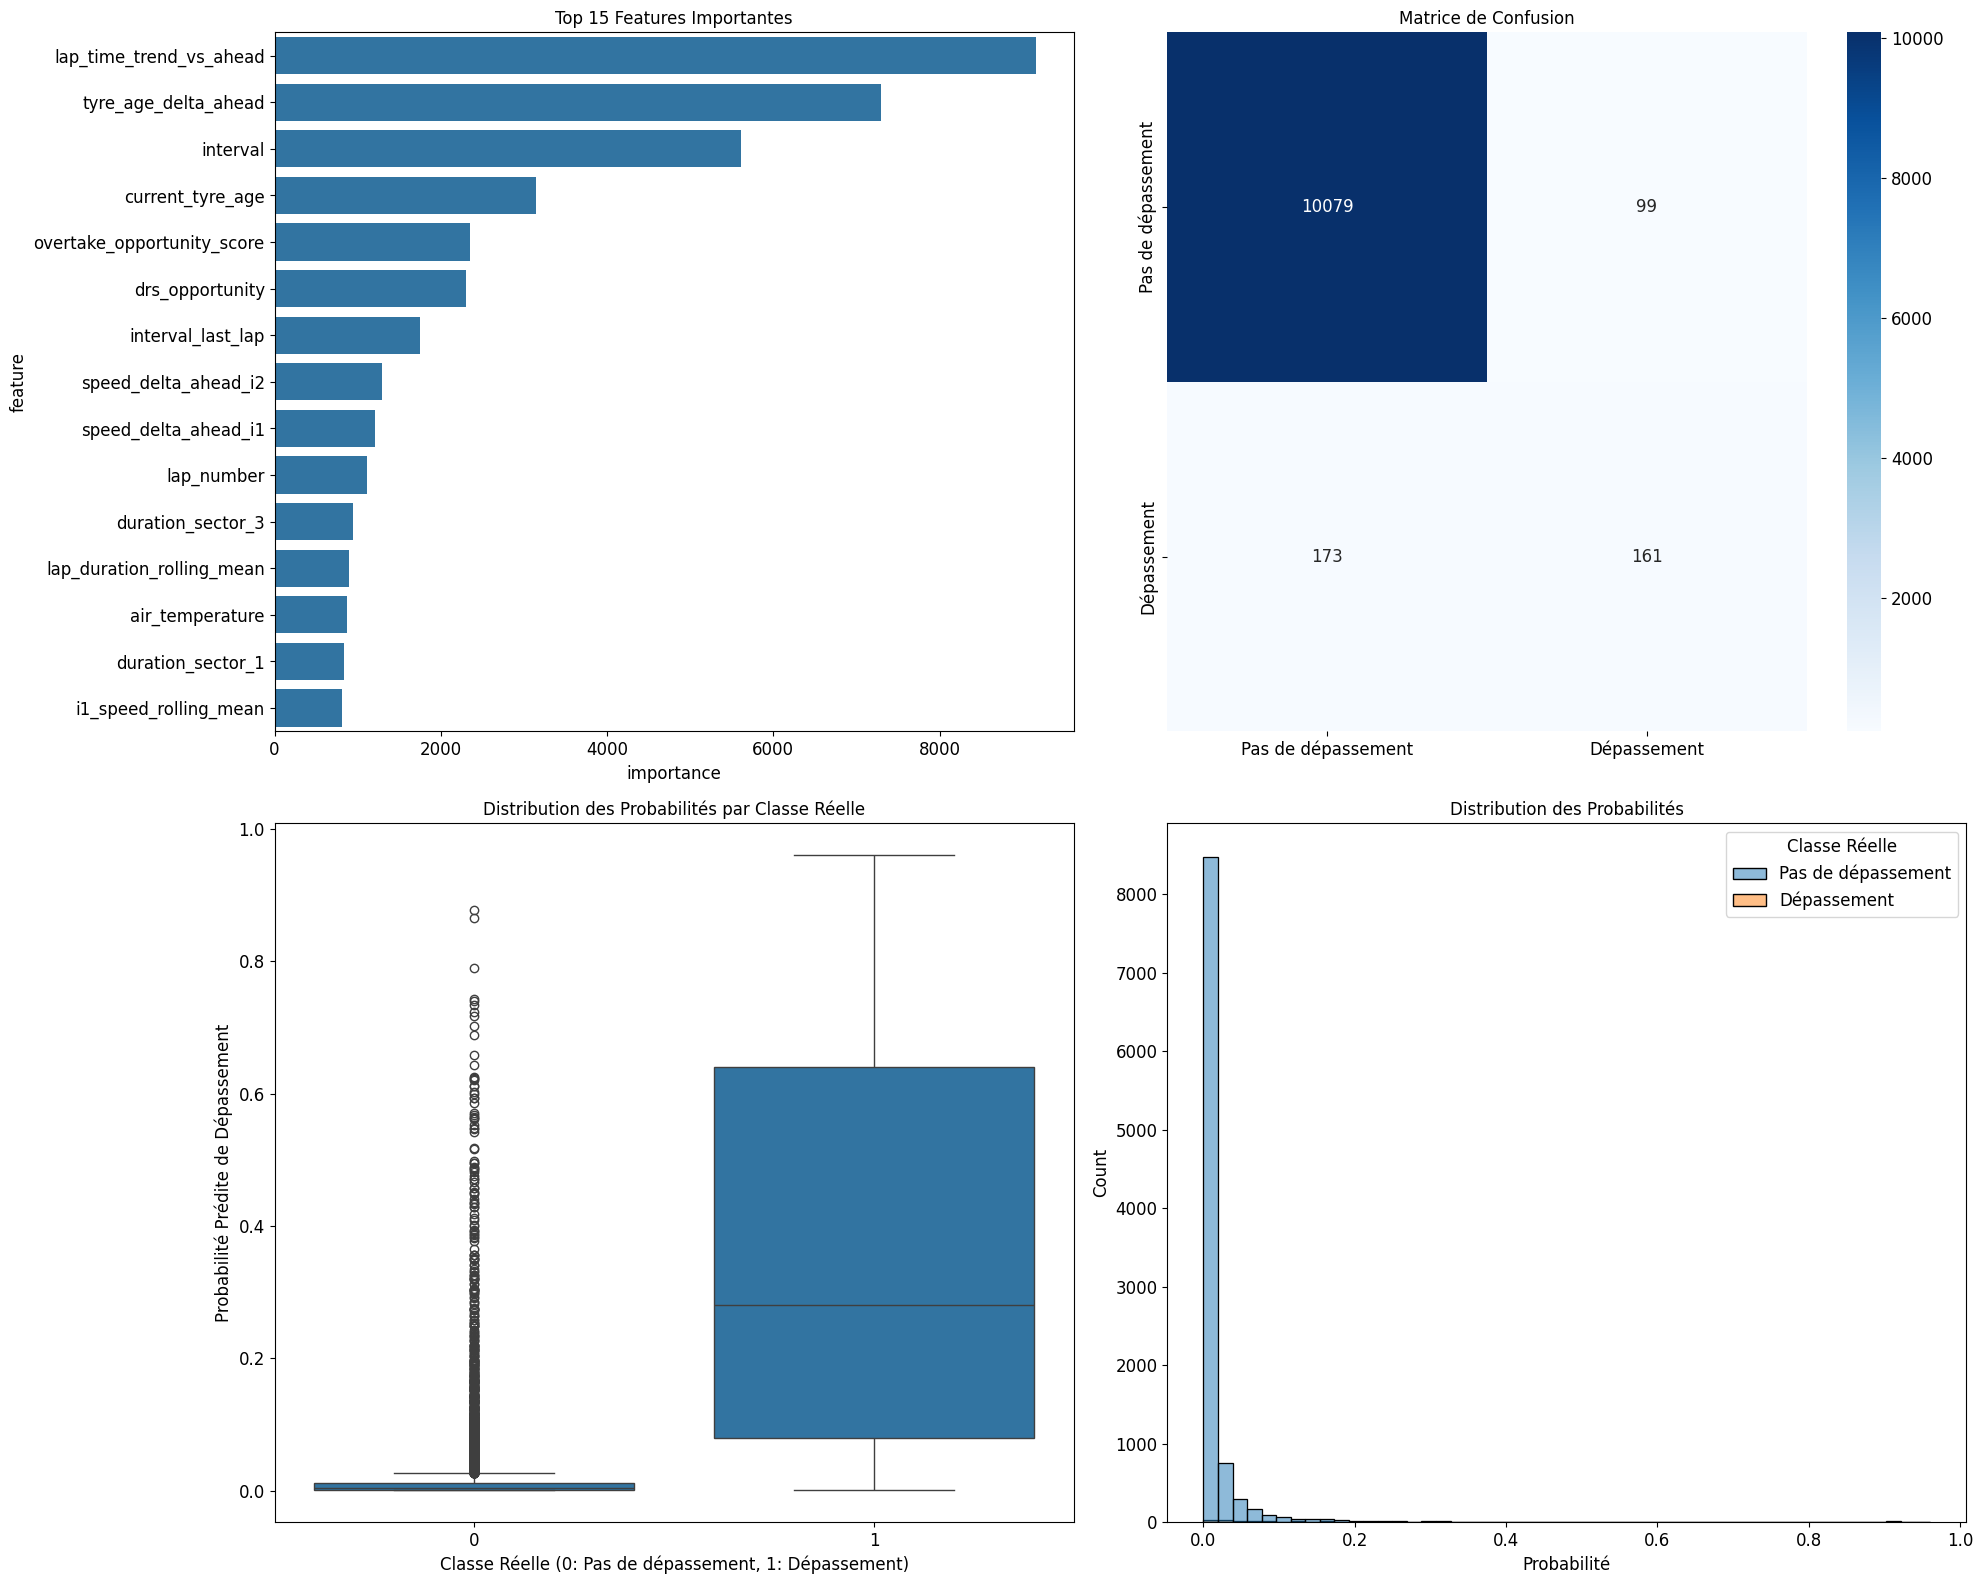

In [57]:
# Après l'entraînement de votre modèle
fig, report, feature_imp, probabilities = evaluate_model_with_probabilities(
    final_model, X_test, y_test, threshold=0.3
)

In [58]:
def visualize_random_predictions(model, X_test, y_test, n_samples=10):
    """
    Visualise les prédictions pour n tours aléatoires dans le cas d'une classification binaire
    
    Args:
        model: Le modèle entraîné
        X_test: Données de test
        y_test: Labels de test (0 ou 1)
        n_samples: Nombre de tours à visualiser
    """
    # Utilisation du timestamp actuel comme graine
    current_seed = int(time.time() * 1000) % 100000
    np.random.seed(current_seed)
    
    # Sélection aléatoire des indices
    total_samples = len(X_test)
    if total_samples < n_samples:
        n_samples = total_samples
        logger.warning(f"Nombre d'échantillons réduit à {total_samples} (taille maximale disponible)")
    
    random_indices = np.random.choice(total_samples, n_samples, replace=False)
    
    # Création de la figure avec n_samples subplots
    fig = plt.figure(figsize=(15, n_samples * 3))
    
    # Obtention des probabilités pour tous les échantillons
    y_pred_proba = model.predict(X_test.iloc[random_indices])
    y_true = y_test[random_indices]
    
    # Création d'un subplot pour chaque tour
    for idx, (i, proba) in enumerate(zip(random_indices, y_pred_proba), 1):
        ax = fig.add_subplot(n_samples, 1, idx)
        
        # Création du DataFrame pour le graphique
        proba_data = pd.DataFrame({
            'Classe': ['Pas de dépassement', 'Dépassement'],
            'Probabilité': [1 - proba, proba]  # Probabilités pour chaque classe
        })
        
        # Couleurs des barres
        colors = ['lightgray'] * 2
        true_class = y_true[idx-1]
        pred_class = int(proba > 0.3)
        
        colors[true_class] = 'lightgreen'  # Vraie classe en vert
        if pred_class != true_class:
            colors[pred_class] = 'lightcoral'  # Prédiction incorrecte en rouge
        
        # Création du bar plot
        bars = ax.bar(proba_data['Classe'], proba_data['Probabilité'], color=colors)
        
        # Ajout des valeurs sur les barres
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.2%}',
                   ha='center', va='bottom')
        
        # Formatage
        ax.set_ylim(0, 1)
        ax.set_ylabel('Probabilité')
        
        # Récupération du numéro de tour
        lap_number = X_test.iloc[i]['lap_number']
        ax.set_title(f'Index {i}, Tour {int(lap_number)} (seed: {current_seed})', pad=20)
        
        # Rotation des labels
        plt.xticks(rotation=45, ha='right')
        
        # Légende personnalisée
        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor='lightgreen', label='Vraie classe'),
            Patch(facecolor='lightcoral', label='Prédiction incorrecte'),
            Patch(facecolor='lightgray', label='Autres classes')
        ]
        ax.legend(handles=legend_elements, loc='upper right')
        
        # Ajout des métriques supplémentaires
        true_class_label = "Dépassement" if true_class == 1 else "Pas de dépassement"
        pred_class_label = "Dépassement" if pred_class == 1 else "Pas de dépassement"
        metrics_text = (f'Vraie classe: {true_class_label}\n'
                       f'Prédiction: {pred_class_label}\n'
                       f'Probabilité de dépassement: {proba:.2%}')
        
        ax.text(0.02, 0.98, metrics_text, 
                transform=ax.transAxes, 
                verticalalignment='top',
                bbox=dict(facecolor='white', alpha=0.8))
    
    plt.tight_layout()
    return fig

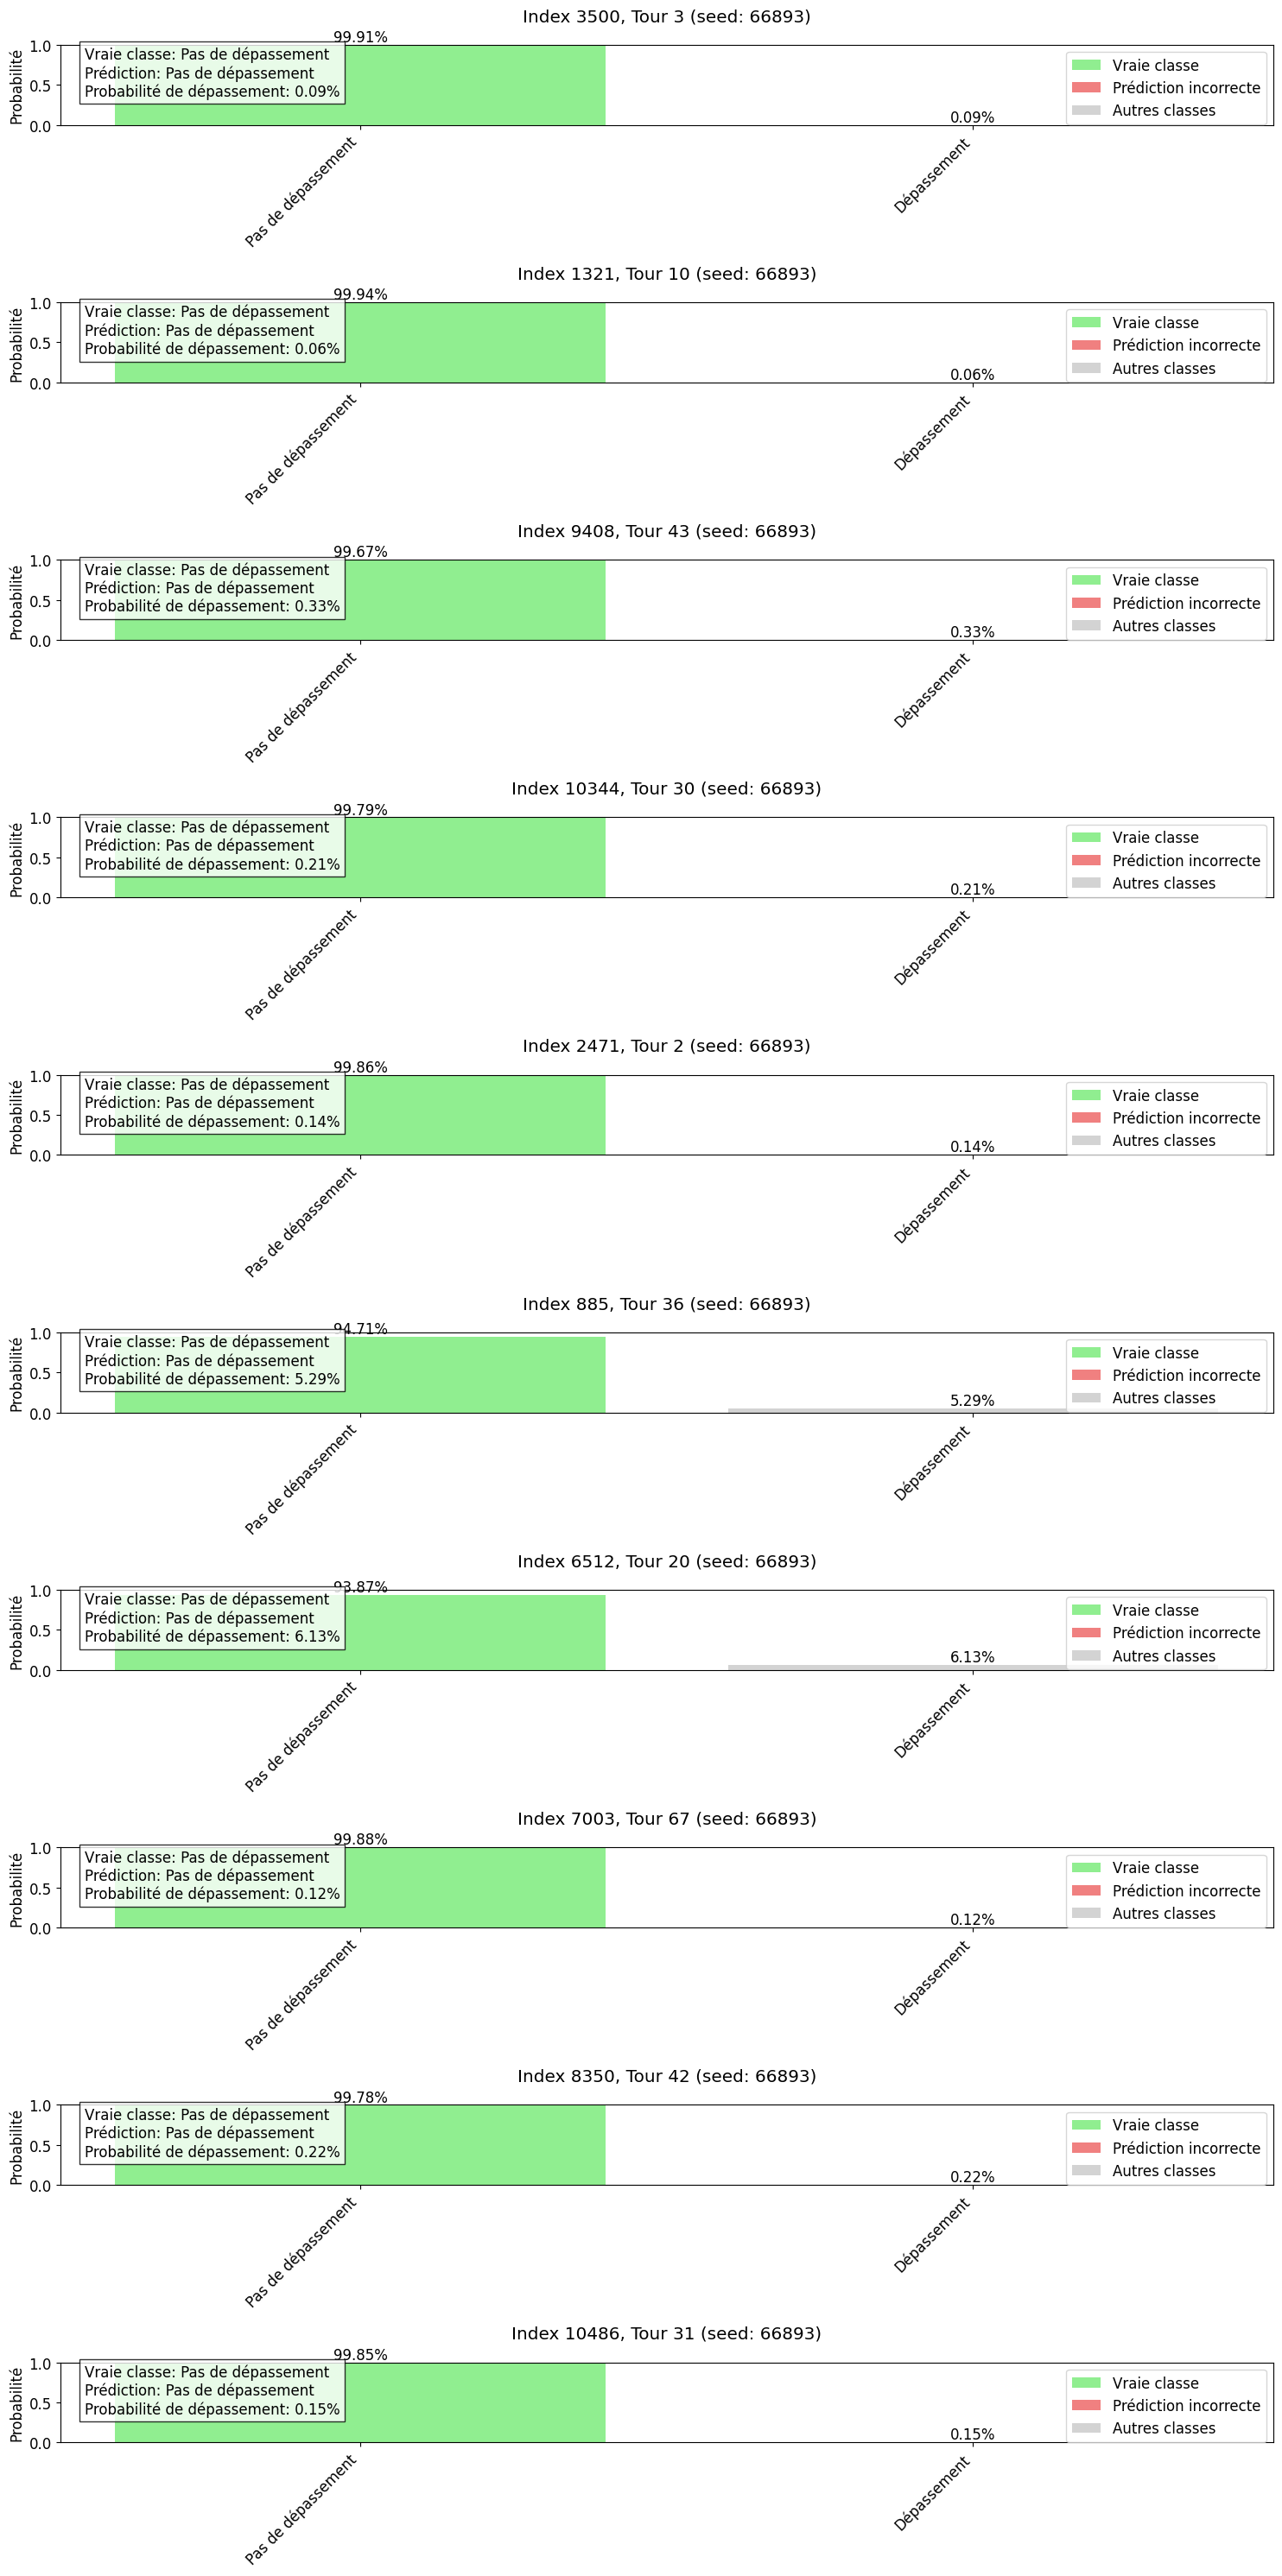

In [59]:
# Création des visualisations pour 10 tours aléatoires
fig = visualize_random_predictions(
    model=final_model,
    X_test=X_test,
    y_test=y_test,
    n_samples=10
)

In [60]:
 # Sauvegarde des résultats
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_dir = Path("results") / timestamp
save_dir.mkdir(parents=True, exist_ok=True)
    
fig.savefig(save_dir / "visualizations.png")
final_model.save_model(save_dir / "model.txt")
feature_imp.to_csv(save_dir / "feature_importance.csv")
with open(save_dir / "report.txt", "w") as f:
    f.write(report)
    
duration = datetime.now() - start_time
logger.info(f"Processus terminé! Durée totale: {duration}")
logger.info(f"Résultats sauvegardés dans: {save_dir}")

2025-01-19 02:47:48,509 - INFO - Processus terminé! Durée totale: 0:22:14.398440
2025-01-19 02:47:48,510 - INFO - Résultats sauvegardés dans: results\20250119_024748


In [61]:
def predict_and_save_results_binary(model, X_test, label_encoder, cat_features, output_dir="predictions", threshold=0.3):
    """
    Réalise les prédictions sur l'ensemble de test pour une classification binaire,
    organise les données par session_key, driver_number et lap_number,
    puis sauvegarde le tout dans des fichiers CSV et JSON dans un dossier spécifique.

    Args:
        model: Le modèle LightGBM entraîné.
        X_test: Le DataFrame de test (features).
        label_encoder: Le LabelEncoder utilisé pour encoder la target (doit avoir 2 classes: True et False).
        cat_features: Liste des features catégorielles
        output_dir: Le dossier de sortie pour les fichiers de prédictions.
        threshold: Le seuil de probabilité pour la classe positive (True).
    """

    # 1. Réaliser les prédictions (probabilités)
    logger.info("Réalisation des prédictions sur l'ensemble de test...")
    y_pred_proba = model.predict(X_test, categorical_feature=cat_features)

    # 2. Appliquer le seuil pour obtenir les prédictions binaires
    logger.info(f"Application du seuil de {threshold} pour les prédictions...")
    y_pred = (y_pred_proba >= threshold).astype(int)  # Classe positive (True) si proba >= seuil

    # 3. Créer un DataFrame avec les résultats
    logger.info("Création du DataFrame de résultats...")
    predictions_df = pd.DataFrame({
        "proba_False": 1 - y_pred_proba,
        "proba_True": y_pred_proba,
        "prediction": y_pred
    })
    
    # 4. Ajouter les colonnes 'session_key', 'driver_number', 'lap_number'
    logger.info("Ajout des colonnes 'session_key', 'driver_number', 'lap_number'...")
    predictions_df['session_key'] = X_test['session_key'].values.astype(int)
    predictions_df['driver_number'] = X_test['driver_number'].values.astype(int)
    predictions_df['lap_number'] = X_test['lap_number'].values.astype(int)

    # 5. Réorganiser les colonnes
    logger.info("Réorganisation des colonnes...")
    cols = ['session_key', 'driver_number', 'lap_number', 'prediction', 'proba_False', 'proba_True']
    predictions_df = predictions_df[cols]

    # 6. Créer le dossier de sortie
    output_path = Path(output_dir) / "predictions_depassements" # Adaptez le nom du sous-dossier
    output_path.mkdir(parents=True, exist_ok=True)

    # 7. Sauvegarder en CSV
    csv_filename = output_path / "predictions_depassements.csv" # Adaptez le nom du fichier
    logger.info(f"Sauvegarde des prédictions en CSV dans {csv_filename}...")
    predictions_df.to_csv(csv_filename, index=False)
    logger.info("Sauvegarde en CSV terminée!")

    # 8. Organiser les données pour le JSON
    logger.info("Organisation des données pour le JSON...")
    json_data = {"sessions": {}}
    for _, row in predictions_df.iterrows():
        session_key = int(row['session_key'])
        driver_number = int(row['driver_number'])
        lap_number = int(row['lap_number'])

        if session_key not in json_data["sessions"]:
            json_data["sessions"][session_key] = {"drivers": {}}
        if driver_number not in json_data["sessions"][session_key]["drivers"]:
            json_data["sessions"][session_key]["drivers"][driver_number] = {"laps": {}}

        json_data["sessions"][session_key]["drivers"][driver_number]["laps"][lap_number] = {
            "predictions": row.drop(['session_key', 'driver_number', 'lap_number']).to_dict()
        }

    # 9. Sauvegarder en JSON
    json_filename = output_path / "predictions_depassements.json" # Adaptez le nom du fichier
    logger.info(f"Sauvegarde des prédictions en JSON dans {json_filename}...")
    with open(json_filename, 'w') as f:
        json.dump(json_data, f, indent=4)
    logger.info("Sauvegarde en JSON terminée!")

In [62]:
# Appel de la fonction pour générer et sauvegarder les prédictions (classification binaire)
predict_and_save_results_binary(
    final_model,
    X_test,
    label_encoder,
    cat_features,
    output_dir="predictions",
    threshold=0.3
)

2025-01-19 02:47:48,529 - INFO - Réalisation des prédictions sur l'ensemble de test...
2025-01-19 02:47:48,543 - INFO - Application du seuil de 0.3 pour les prédictions...
2025-01-19 02:47:48,544 - INFO - Création du DataFrame de résultats...
2025-01-19 02:47:48,545 - INFO - Ajout des colonnes 'session_key', 'driver_number', 'lap_number'...
2025-01-19 02:47:48,547 - INFO - Réorganisation des colonnes...
2025-01-19 02:47:48,549 - INFO - Sauvegarde des prédictions en CSV dans predictions\predictions_depassements\predictions_depassements.csv...
2025-01-19 02:47:48,583 - INFO - Sauvegarde en CSV terminée!
2025-01-19 02:47:48,584 - INFO - Organisation des données pour le JSON...
2025-01-19 02:47:50,134 - INFO - Sauvegarde des prédictions en JSON dans predictions\predictions_depassements\predictions_depassements.json...
2025-01-19 02:47:50,397 - INFO - Sauvegarde en JSON terminée!
